# Cancellation and Non-Renewal: Model Comparison
## Logistic Regression, Random Forest, and XGBoost

**Development period:** 2021–2022 · **Target:** `LAPSE`  
**Source:** committed model reports retrieved on 18 November 2026.

This notebook aligns the group's saved primary pipelines in one course scorecard and compares targeting at decile checkpoints. It uses report CSVs only, without fitting models or loading the processed policy-level dataset. The XGBoost-specific report is `07c_lapse_xgb_report.ipynb`.

## 1. Setup and Source Validation

In [1]:
# Load the libraries used for report tables and figures.
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'figure.dpi': 110})
GREEN, BLUE, GRAY = '#2e8b57', '#377eb8', '#757575'
SCOPE = '2021-2022'
PRIMARY_MODEL = 'XGBoost V2'

In [2]:
# Find the reports folder in the extracted package or project repository.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'reports/lapse_xgb_run.json').exists()), None)
assert ROOT is not None, 'Extract the full submission package before running this notebook.'
REPORTS = ROOT / 'reports'
run = json.loads((REPORTS / 'lapse_xgb_run.json').read_text())
xgb_deciles = pd.read_csv(REPORTS / 'lapse_xgb_test_deciles.csv').sort_values('risk_group')
xgb_confusion = pd.read_csv(REPORTS / 'lapse_xgb_test_confusion.csv')
xgb_metrics = pd.read_csv(REPORTS / 'lapse_xgb_test_metrics.csv')
xgb_overall = xgb_metrics[xgb_metrics.scope.astype(str).eq(SCOPE)]
primary_metrics = xgb_overall[xgb_overall.model.eq(PRIMARY_MODEL)].iloc[0]
N = int(xgb_deciles.rows.sum())
EVENTS = int(xgb_deciles.lapses.sum())
RATE = EVENTS / N
assert run['target'] == 'LAPSE' and run['selected_model'] == PRIMARY_MODEL
assert len(xgb_deciles) == 10 and xgb_deciles.risk_group.tolist() == list(range(1, 11))
assert int(primary_metrics.rows) == N
np.testing.assert_allclose(primary_metrics.actual_rate, RATE)
np.testing.assert_allclose(xgb_deciles.actual, xgb_deciles.lapses / xgb_deciles.rows)
np.testing.assert_allclose(xgb_deciles.share_of_lapses, xgb_deciles.lapses / EVENTS)
np.testing.assert_allclose(xgb_deciles.cumulative_capture, xgb_deciles.lapses.cumsum() / EVENTS)
np.testing.assert_allclose(primary_metrics.top_decile_capture, xgb_deciles.share_of_lapses.iloc[0])
np.testing.assert_allclose(primary_metrics.predicted_rate,
    np.average(xgb_deciles.predicted, weights=xgb_deciles.rows), rtol=1e-6)
print(f'Development population: {N:,} policy-years; {EVENTS:,} lapses ({RATE:.2%}).')

Development population: 7,105,637 policy-years; 854,084 lapses (12.02%).


In [3]:
# Verify that all input files match the recorded GitHub snapshot.
SOURCE_HASHES = {'reports/lapse_xgb_run.json': 'a970708ae6fb4b46e8523a4f747fdc3963531509', 'reports/lapse_xgb_test_deciles.csv': 'eb4491c6b0fb228ad3ca964d67d1cd4080af0251', 'reports/lapse_xgb_test_confusion.csv': '1f4d110fb5bc32504596fce7c5e241afbb2eeef6', 'reports/lapse_xgb_test_metrics.csv': '96f5433d33f7ece90b84c2870994e9c17b0411ee', 'reports/lapse_xgb_importance.csv': '8e13f46b0619883114827b99df559bef76d91f09', 'reports/lapse_xgb_test_auc.csv': '04d6ed6f7831895d3e0ad5451cf080f7be91c15b', 'reports/lapse_xgb_tuning.csv': '2ef4a0ad2e9032296a61ac8a526fd707bc8ee467', 'reports/lapse_xgb_sensitivity.csv': '64c9e4082408ee3daf3d4cef34cc396eed75c83e', 'reports/lapse_baseline_logreg_test_deciles.csv': '4a3a2477593fbd6e1e625937c2b8dd65ac928480', 'reports/lapse_rf_test_deciles.csv': 'b331c48ade6b3e12533632cb829fae0baa878bb0', 'reports/lapse_baseline_logreg_test_confusion.csv': 'e9cbe232a4aae79b3942e00a7c00fd5e81da28dc', 'reports/lapse_rf_test_confusion.csv': 'cbe4b635821c59fcdbde536c179c4780c8a72fbd', 'reports/lapse_baseline_logreg_test_metrics.csv': '60e399210209fe823135a2830fb557a47b6ad581', 'reports/lapse_rf_test_metrics.csv': '1b7dd968df843572755f203d32082fd6e3a8cad0', 'reports/lapse_rf_test_auc.csv': 'b2624c397aa80b56b9ff21a5f615ce4ce9039e6f', 'reports/lapse_rf_run.json': 'da33d8d17469b63bd796bf89ba9cd107b251e1b3'}
for relative, expected in SOURCE_HASHES.items():
    data = (ROOT / relative).read_bytes()
    observed = hashlib.sha1(f'blob {len(data)}\0'.encode() + data).hexdigest()
    assert observed == expected, f'Source changed: {relative}. Reconcile the input snapshot before rerunning.'
print(f'Verified {len(SOURCE_HASHES)} source reports against their Git blob hashes.')

Verified 16 source reports against their Git blob hashes.


In [4]:
def validate_confusions(table):
    """Reconcile reported metrics with the saved confusion counts."""
    counts = table[['TP', 'FP', 'FN', 'TN']]
    assert counts.ge(0).all().all()
    assert np.equal(counts.to_numpy(), np.floor(counts.to_numpy())).all()
    assert counts.sum(axis=1).eq(N).all()
    assert (table.TP + table.FN).eq(EVENTS).all()
    positive = table.TP + table.FP
    precision = np.divide(table.TP, positive, out=np.zeros(len(table)), where=positive > 0)
    recall = table.TP / EVENTS
    f1 = np.divide(2 * precision * recall, precision + recall,
        out=np.zeros(len(table)), where=(precision + recall) > 0)
    checks = {'flagged_share': positive / N, 'accuracy': (table.TP + table.TN) / N,
              'precision': precision, 'recall': recall, 'f1': f1, 'lift': precision / RATE}
    for metric, expected in checks.items():
        np.testing.assert_allclose(table[metric], expected, rtol=1e-9, atol=1e-12)


def save_table_image(table, title, filename):
    """Save a legible, presentation-ready image of a formatted table."""
    fig, ax = plt.subplots(figsize=(12, max(2.6, .34 * (len(table) + 3))))
    ax.axis('off')
    visual = ax.table(cellText=table.to_numpy(), colLabels=table.columns,
        cellLoc='center', loc='center')
    visual.auto_set_font_size(False)
    visual.set_fontsize(9)
    visual.auto_set_column_width(list(range(len(table.columns))))
    visual.scale(1, 1.6)
    for (row, column), cell in visual.get_celld().items():
        cell.set_edgecolor('white')
        cell.set_facecolor('#e9efeb' if row == 0 else ('#f4f4f4' if row % 2 == 0 else 'white'))
        if row == 0:
            cell.set_text_props(weight='bold')
    ax.set_title(title, fontsize=12, pad=15)
    fig.tight_layout()
    fig.savefig(REPORTS / filename, dpi=180, bbox_inches='tight')
    plt.show()


def percent_table(table, columns, decimals=1):
    result = table.copy()
    for column in columns:
        result[column] = result[column].map(lambda value: f'{value:.{decimals}%}')
    return result

In [5]:
# Keep the same four operating-rule labels used in 06b and the RF notebook.
RULES = ['riskiest 10% in train', 'riskiest 20% in train',
         'riskiest 30% in train', 'p >= 0.5 (default)']
validate_confusions(xgb_confusion)
primary_cm = xgb_confusion[xgb_confusion.model.eq(PRIMARY_MODEL)].copy()
primary_cm = primary_cm[primary_cm.rule.isin(RULES)]
primary_cm = primary_cm.set_index('rule').loc[RULES].reset_index()
assert len(primary_cm) == 4
middle = primary_cm[primary_cm.rule.eq('riskiest 20% in train')].iloc[0]

## 2. Shared Course Scorecard
Each model's own training-derived 10%, 20%, and 30% probability cut-offs are applied to the same development period. XGBoost and logistic-regression thresholds use training fitted scores; RF thresholds use honest training scores recorded by its pipeline. Realized flagged shares differ between models and periods.

Only the primary logistic-regression, RF 2, and XGBoost V2 rows are combined. Logistic rows repeated inside the RF file are excluded.

In [6]:
# Combine the three primary classifiers at the agreed operating rules.
lr_cm = pd.read_csv(REPORTS / 'lapse_baseline_logreg_test_confusion.csv')
lr_cm['model'] = 'Logistic regression'
rf_cm = pd.read_csv(REPORTS / 'lapse_rf_test_confusion.csv')
rf_cm = rf_cm[rf_cm.model.eq('RF 2')].copy().assign(model='Random Forest (RF 2)')
xgb_cm = primary_cm.copy()
COURSE_COLUMNS = ['model', 'rule', 'threshold', 'flagged_share', 'TP', 'FP', 'FN', 'TN',
                  'accuracy', 'precision', 'recall', 'f1', 'lift']
course = pd.concat([lr_cm[COURSE_COLUMNS], rf_cm[COURSE_COLUMNS], xgb_cm[COURSE_COLUMNS]],
    ignore_index=True)
course = course[course.rule.isin(RULES)].copy()
validate_confusions(course)
assert len(course) == 12 and not course.duplicated(['model', 'rule']).any()
course['rule_order'] = course.rule.map({rule: i for i, rule in enumerate(RULES)})
course = course.sort_values(['rule_order', 'model']).drop(columns='rule_order').reset_index(drop=True)
display(course[['model', 'rule', 'flagged_share', 'accuracy', 'precision', 'recall', 'f1', 'lift']].round(5))
course.to_csv(REPORTS / 'lapse_course_comparison_test.csv', index=False)

,model,rule,flagged_share,accuracy,precision,recall,f1,lift
0,Logistic regression,riskiest 10% in train,0.07212,0.84708,0.27314,0.16388,0.20485,2.27240
1,Random Forest (RF 2),riskiest 10% in train,0.04529,0.86358,0.32095,0.12094,0.17569,2.67018
2,XGBoost V2,riskiest 10% in train,0.05156,0.85975,0.30553,0.13107,0.18344,2.54193
3,Logistic regression,riskiest 20% in train,0.14215,0.80659,0.24246,0.28673,0.26274,2.01716
4,Random Forest (RF 2),riskiest 20% in train,0.10019,0.83378,0.27035,0.22535,0.24581,2.24919
5,XGBoost V2,riskiest 20% in train,0.10606,0.82954,0.26305,0.23210,0.24661,2.18847
6,Logistic regression,riskiest 30% in train,0.21394,0.75984,0.21964,0.39094,0.28126,1.82734
7,Random Forest (RF 2),riskiest 30% in train,0.18572,0.78245,0.23791,0.36760,0.28887,1.97932
8,XGBoost V2,riskiest 30% in train,0.17481,0.78740,0.23570,0.34279,0.27934,1.96096
9,Logistic regression,p >= 0.5 (default),0.00386,0.87916,0.41657,0.01336,0.02589,3.46572


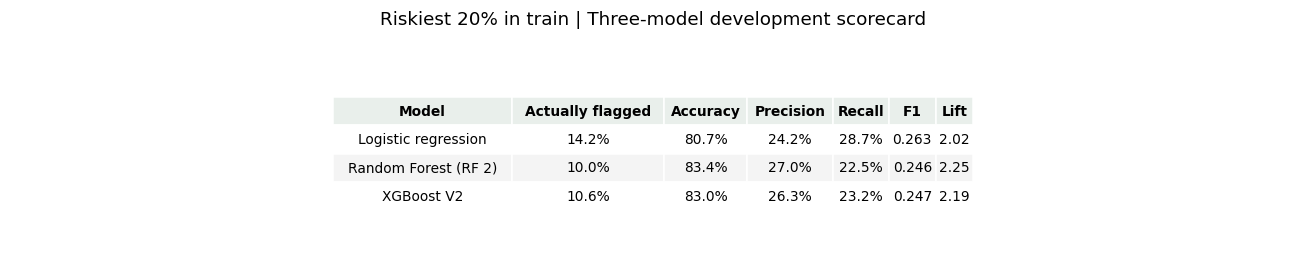

In [7]:
# Save the central operating-rule comparison as a presentation-ready table.
middle_comparison = course[course.rule.eq('riskiest 20% in train')].copy()
view = middle_comparison[['model', 'flagged_share', 'accuracy', 'precision', 'recall', 'f1', 'lift']]
view = percent_table(view, ['flagged_share', 'accuracy', 'precision', 'recall'])
view['f1'] = view.f1.map(lambda value: f'{value:.3f}')
view['lift'] = view.lift.map(lambda value: f'{value:.2f}')
view.columns = ['Model', 'Actually flagged', 'Accuracy', 'Precision', 'Recall', 'F1', 'Lift']
save_table_image(view, 'Riskiest 20% in train | Three-model development scorecard',
    'fig_lapse_course_comparison_20_train.png')

## 3. Matched Decile Targeting
The following analysis targets the highest-risk one, two, or three **development deciles**. This is separate from the training-threshold rules above. The XGBoost file numbers the highest-risk group as 1; the LR/RF files number it as 10. Each source is explicitly reordered from highest to lowest predicted risk.

Only observed decile checkpoints are available. The curves connect those checkpoints; no 1% or 5% targeting results are reconstructed from aggregate data. Cumulative group sizes can differ by a few rows because deciles divide an indivisible population.

In [8]:
def decile_checkpoints(table, key, descending, model):
    """Convert saved decile counts into exact cumulative targeting metrics."""
    table = table.sort_values(key, ascending=not descending).reset_index(drop=True).copy()
    assert len(table) == 10 and table[key].nunique() == 10
    assert table.rows.sum() == N and table.lapses.sum() == EVENTS
    assert table.rows.gt(0).all() and table.lapses.between(0, table.rows).all()
    assert np.equal(table[['rows', 'lapses']], np.floor(table[['rows', 'lapses']])).all().all()
    assert table.predicted.is_monotonic_decreasing
    np.testing.assert_allclose(table.actual, table.lapses / table.rows)
    flagged = table.rows.cumsum().to_numpy(dtype='int64')
    tp = table.lapses.cumsum().to_numpy(dtype='int64')
    fp, fn = flagged - tp, EVENTS - tp
    tn = N - flagged - fn
    precision, recall = tp / flagged, tp / EVENTS
    f1 = np.divide(2 * precision * recall, precision + recall,
        out=np.zeros_like(precision), where=(precision + recall) > 0)
    return pd.DataFrame(dict(model=model, top_deciles=np.arange(1, 11),
        flagged_rows=flagged, flagged_share=flagged / N, TP=tp, FP=fp, FN=fn, TN=tn,
        accuracy=(tp + tn) / N, precision=precision, recall=recall, f1=f1, lift=precision / RATE))

In [9]:
# Use actual saved counts for every model, with no interpolated observations.
lr_deciles = pd.read_csv(REPORTS / 'lapse_baseline_logreg_test_deciles.csv')
rf_deciles = pd.read_csv(REPORTS / 'lapse_rf_test_deciles.csv')
targeting = pd.concat([
    decile_checkpoints(lr_deciles, 'decile', True, 'Logistic regression'),
    decile_checkpoints(rf_deciles, 'decile', True, 'Random Forest (RF 2)'),
    decile_checkpoints(xgb_deciles, 'risk_group', False, PRIMARY_MODEL)
], ignore_index=True)
validate_confusions(targeting)
targeting.to_csv(REPORTS / 'lapse_decile_targeting_comparison.csv', index=False)
scorecard = targeting[targeting.top_deciles.isin([1, 2, 3])].copy()
scorecard.to_csv(REPORTS / 'lapse_same_share_scorecard.csv', index=False)
display(scorecard[['model', 'flagged_share', 'accuracy', 'precision', 'recall', 'f1', 'lift']].round(5))

,model,flagged_share,accuracy,precision,recall,f1,lift
0,Logistic regression,0.1,0.83161,0.25905,0.21552,0.23528,2.15516
1,Logistic regression,0.2,0.76929,0.22371,0.37224,0.27946,1.86118
2,Logistic regression,0.3,0.69914,0.19889,0.49641,0.28400,1.65470
10,Random Forest (RF 2),0.1,0.83390,0.27051,0.22506,0.24570,2.25056
11,Random Forest (RF 2),0.2,0.77334,0.23386,0.38912,0.29214,1.94559
12,Random Forest (RF 2),0.3,0.70567,0.20979,0.52360,0.29955,1.74534
20,XGBoost V2,0.1,0.83317,0.26685,0.22201,0.24237,2.22005
21,XGBoost V2,0.2,0.77109,0.22823,0.37976,0.28511,1.89878
22,XGBoost V2,0.3,0.70288,0.20513,0.51199,0.29291,1.70663


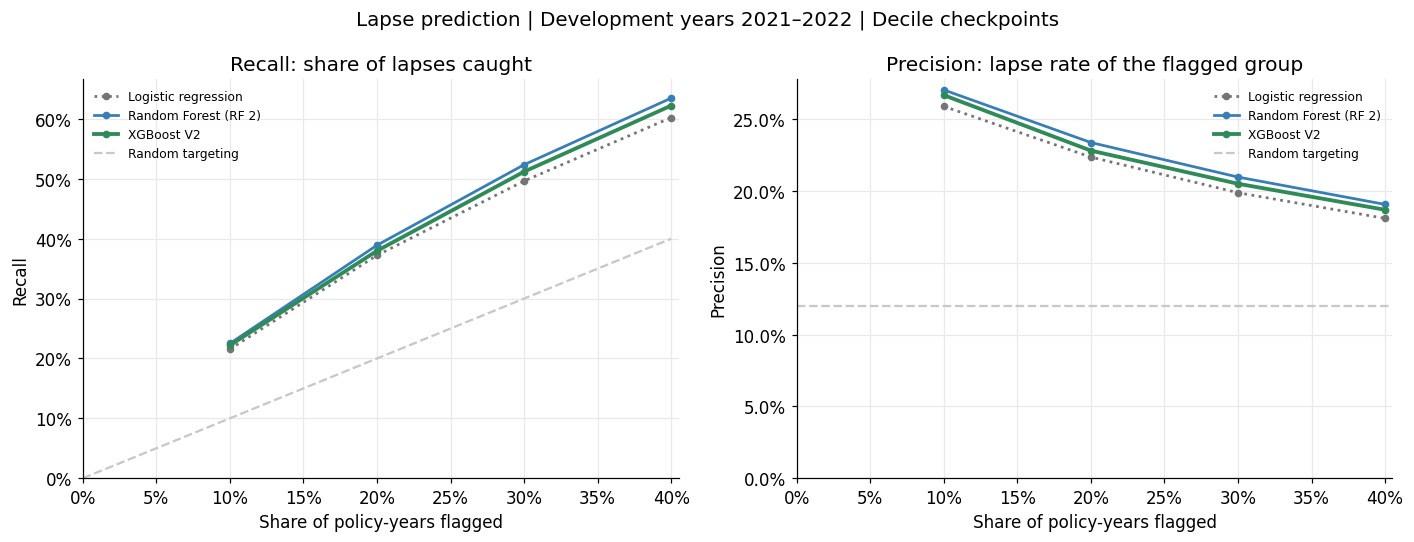

In [10]:
# Match the example's two-panel layout using the available decile checkpoints.
styles = {'Logistic regression': dict(color=GRAY, linestyle=':', linewidth=1.8),
          'Random Forest (RF 2)': dict(color=BLUE, linewidth=1.8),
          PRIMARY_MODEL: dict(color=GREEN, linewidth=2.5)}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, style in styles.items():
    points = targeting[targeting.model.eq(name) & targeting.top_deciles.le(4)]
    for ax, metric in zip(axes, ['recall', 'precision']):
        ax.plot(points.flagged_share, points[metric], marker='o', markersize=4, label=name, **style)
axes[0].plot([0, .4], [0, .4], '--', color='#c8c8c8', label='Random targeting')
axes[1].axhline(RATE, linestyle='--', color='#c8c8c8', label='Random targeting')
for ax, metric, title in zip(axes, ['Recall', 'Precision'],
    ['Recall: share of lapses caught', 'Precision: lapse rate of the flagged group']):
    ax.set(title=title, xlabel='Share of policy-years flagged', ylabel=metric,
           xlim=(0, .405), ylim=(0, None))
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0 if metric == 'Recall' else 1))
    ax.grid(color='#e9e9e9')
    ax.legend(frameon=False, fontsize=8, loc='upper left' if metric == 'Recall' else 'upper right')
fig.suptitle('Lapse prediction | Development years 2021–2022 | Decile checkpoints', fontsize=13)
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_recall_precision_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

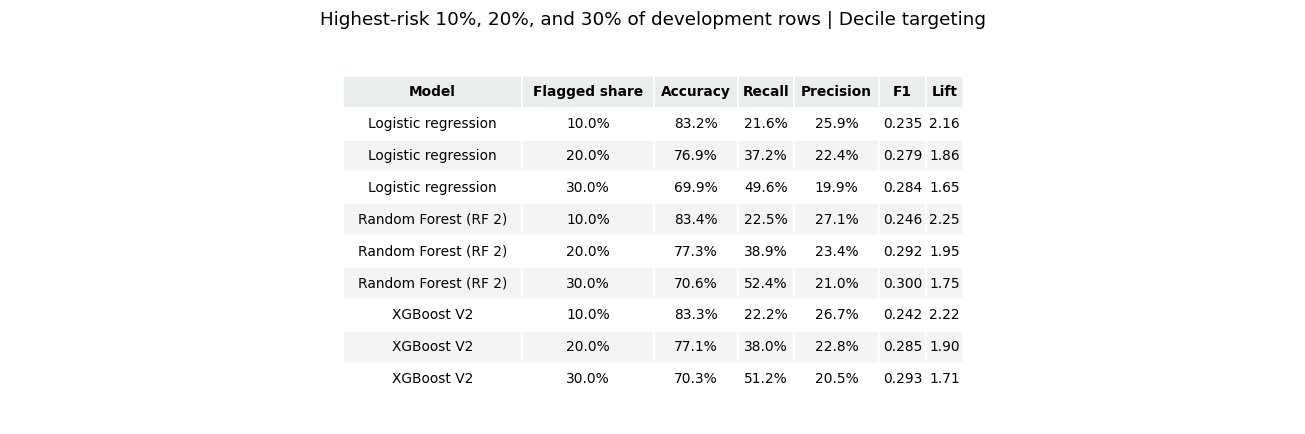

In [11]:
# Export an exact-value targeting scorecard beside the curves.
view = scorecard[['model', 'flagged_share', 'accuracy', 'recall', 'precision', 'f1', 'lift']]
view = percent_table(view, ['flagged_share', 'accuracy', 'recall', 'precision'])
view['f1'] = view.f1.map(lambda value: f'{value:.3f}')
view['lift'] = view.lift.map(lambda value: f'{value:.2f}')
view.columns = ['Model', 'Flagged share', 'Accuracy', 'Recall', 'Precision', 'F1', 'Lift']
save_table_image(view, 'Highest-risk 10%, 20%, and 30% of development rows | Decile targeting',
    'fig_lapse_same_share_scorecard.png')

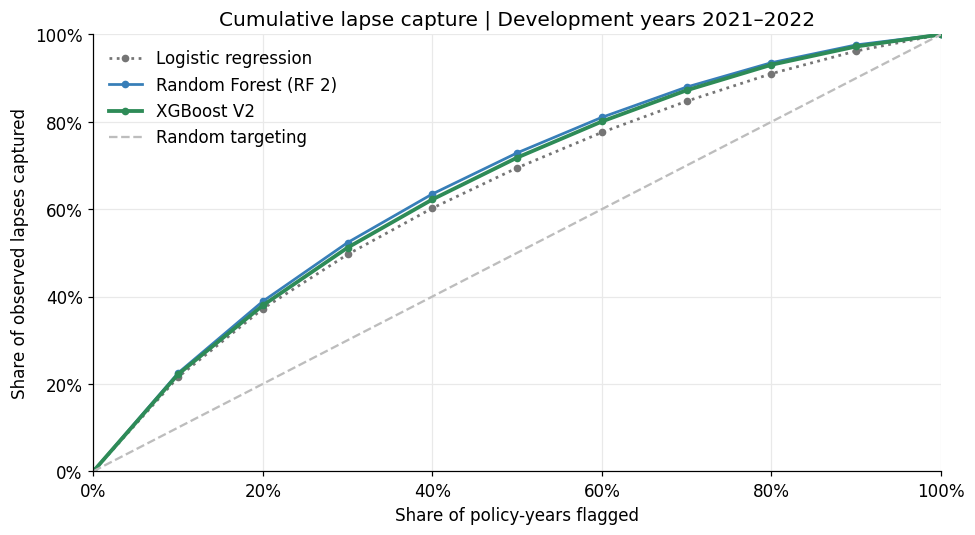

In [12]:
# Show cumulative lapse capture across all ten available targeting checkpoints.
fig, ax = plt.subplots(figsize=(9, 5))
for name, style in styles.items():
    points = targeting[targeting.model.eq(name)]
    ax.plot(np.r_[0, points.flagged_share], np.r_[0, points.recall],
        marker='o', markersize=4, label=name, **style)
ax.plot([0, 1], [0, 1], '--', color='#bdbdbd', label='Random targeting')
ax.set(title='Cumulative lapse capture | Development years 2021–2022',
    xlabel='Share of policy-years flagged', ylabel='Share of observed lapses captured',
    xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(color='#e9e9e9')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_capture_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Probability and Ranking Comparison
The saved aggregate ROC-AUC, log loss, and Brier scores are reported below. Higher ROC-AUC is better; lower log loss and Brier scores are better. AUC values alone cannot reproduce an ROC curve, so no ROC curve is inferred from these summary values.

In [13]:
# Combine the primary models' probability metrics for the same development period.
lr_metrics = pd.read_csv(REPORTS / 'lapse_baseline_logreg_test_metrics.csv')
rf_metrics = pd.read_csv(REPORTS / 'lapse_rf_test_metrics.csv')
lr = lr_metrics[lr_metrics.scope.astype(str).eq(SCOPE) & lr_metrics.model.eq('logistic regression')].iloc[0]
rf = rf_metrics[rf_metrics.scope.astype(str).eq(SCOPE) & rf_metrics.model.eq('RF 2 (tuned)')].iloc[0]
rf_auc = pd.read_csv(REPORTS / 'lapse_rf_test_auc.csv', index_col=0)
records = []
for name, row, auc in [('Logistic regression', lr, lr.roc_auc),
    ('Random Forest (RF 2)', rf, rf_auc.loc['RF 2 (tuned)', SCOPE]),
    (PRIMARY_MODEL, primary_metrics, primary_metrics.roc_auc)]:
    assert int(row.rows) == N
    np.testing.assert_allclose(row.actual_rate, RATE)
    top = targeting[targeting.model.eq(name) & targeting.top_deciles.eq(1)].iloc[0]
    records.append(dict(model=name, roc_auc=float(auc), log_loss=float(row.log_loss),
        brier=float(row.brier), top_decile_capture=float(top.recall),
        actual_rate=RATE, predicted_rate=float(row.predicted_rate)))
probability_comparison = pd.DataFrame(records)
display(probability_comparison.round(5))
probability_comparison.to_csv(REPORTS / 'lapse_probability_comparison_test.csv', index=False)

,model,roc_auc,log_loss,brier,top_decile_capture,actual_rate,predicted_rate
0,Logistic regression,0.65893,0.35128,0.10219,0.21552,0.1202,0.11856
1,Random Forest (RF 2),0.68526,0.34386,0.10047,0.22506,0.1202,0.12054
2,XGBoost V2,0.67674,0.34653,0.10107,0.22201,0.1202,0.11201


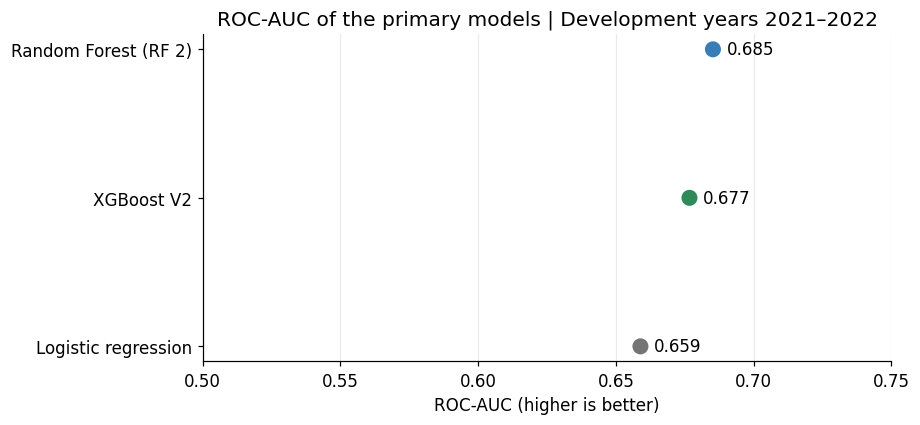

In [14]:
# Compare saved ROC-AUC values without fabricating threshold-level ROC observations.
show = probability_comparison.sort_values('roc_auc')
fig, ax = plt.subplots(figsize=(8.5, 4))
colors = [styles[name]['color'] for name in show.model]
ax.scatter(show.roc_auc, show.model, s=90, c=colors)
for row in show.itertuples(index=False):
    ax.annotate(f'{row.roc_auc:.3f}', (row.roc_auc, row.model), xytext=(9, 0),
        textcoords='offset points', va='center')
ax.set(title='ROC-AUC of the primary models | Development years 2021–2022',
    xlabel='ROC-AUC (higher is better)', xlim=(.5, .75))
ax.grid(axis='x', color='#e9e9e9')
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(REPORTS / 'fig_lapse_auc_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Findings and Interpretation

In [15]:
# Describe observed performance without claiming final-holdout or causal results.
summary = probability_comparison.set_index('model')
x, r, l = summary.loc[PRIMARY_MODEL], summary.loc['Random Forest (RF 2)'], summary.loc['Logistic regression']
display(Markdown(
    f"- All three saved reports cover **{N:,} policy-years** and **{EVENTS:,} lapses** in 2021–2022.\n"
    f"- XGBoost V2 has aggregate ROC-AUC **{x.roc_auc:.3f}**, compared with **{l.roc_auc:.3f}** for logistic regression "
    f"and **{r.roc_auc:.3f}** for RF 2.\n"
    f"- The highest-risk decile captures **{x.top_decile_capture:.2%}** of lapses for XGBoost, "
    f"**{l.top_decile_capture:.2%}** for logistic regression, and **{r.top_decile_capture:.2%}** for RF 2.\n"
    f"- In these saved development reports, XGBoost improves aggregate ROC-AUC and log loss over logistic regression. "
    f"RF 2 has the highest aggregate ROC-AUC and the lowest log loss and Brier score among the three primary models.\n"
    f"- Training-threshold scorecards and development-decile targeting provide complementary comparisons. "
    f"A nominal 20% training rule does not mean exactly 20% of later policy-years are contacted."
))

- All three saved reports cover **7,105,637 policy-years** and **854,084 lapses** in 2021–2022.
- XGBoost V2 has aggregate ROC-AUC **0.677**, compared with **0.659** for logistic regression and **0.685** for RF 2.
- The highest-risk decile captures **22.20%** of lapses for XGBoost, **21.55%** for logistic regression, and **22.51%** for RF 2.
- In these saved development reports, XGBoost improves aggregate ROC-AUC and log loss over logistic regression. RF 2 has the highest aggregate ROC-AUC and the lowest log loss and Brier score among the three primary models.
- Training-threshold scorecards and development-decile targeting provide complementary comparisons. A nominal 20% training rule does not mean exactly 20% of later policy-years are contacted.

### Scope and Reproducibility
- This is a comparison of recorded pipelines. Sample design, preprocessing, threshold provenance, and feature handling can differ.
- Matching aggregate row counts and lapse totals is a consistency check, not a row-level ID reconciliation.
- Targeting curves contain observed decile checkpoints only. They are not a dense threshold sweep.
- No final-holdout metrics or synthetic results are introduced. Feature importance and model fitting remain in their own notebooks.
- The source reports retain their original contents; the consolidated course, targeting, and probability scorecards use new filenames.

**Source:** [project reports](https://github.com/jmsebastiancarino/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/tree/main/reports), with input blob hashes recorded in `source_manifest.json`.

In [16]:
# Verify the completed exports and preserve the requested decile-file identity.
assert len(course) == 12 and len(targeting) == 30 and len(scorecard) == 9
assert len(probability_comparison) == 3
for relative, expected in SOURCE_HASHES.items():
    data = (ROOT / relative).read_bytes()
    assert hashlib.sha1(f'blob {len(data)}\0'.encode() + data).hexdigest() == expected
print('All source inputs remain unchanged. Comparison tables and figures are saved in reports/.')

All source inputs remain unchanged. Comparison tables and figures are saved in reports/.
